
MASSA CORPORAL POR ATLETA (modelo .osim escalonado)
  Participante 02: 67.11 kg
  Participante 03: 58.79 kg
  Participante 04: 84.19 kg
  Participante 05: 64.88 kg
  Participante 06: 77.66 kg
  Participante 07: 57.73 kg
  Participante 08: 65.71 kg
  Participante 09: 97.23 kg
  Participante 10: 71.79 kg
  Participante 11: 67.75 kg

ESTRUTURA AMOSTRAL E ROTULAGEM
Ciclos: 30 | Atletas: 10
Limiar P75 do momento em valgo normalizado: 0.203 Nm/kg
Classe 1 (elevada sobrecarga): 8 | Classe 0: 22
ATENCAO: a Classe 1 nao tem 7 ciclos. Ajuste o texto da 2.1.6 (n da Classe 1 e da Classe 0) ao valor acima.

Ciclos de Classe 1 por atleta:
Participante  02  03  04  05  06  07  08  09  10  11
classe_1       2   0   1   0   0   0   0   2   3   0
ciclos         3   3   3   3   3   3   3   3   3   3
Momento em valgo (Nm/kg): minimo -0.065 | mediana 0.114 | maximo 0.385

NIVEL 1: GROUPKFOLD ANINHADO (K = 3)
Particao 1: atletas de teste ['02', '05', '08', '11'] | C1 treino 6 / teste 2 | limiar interno 0.0

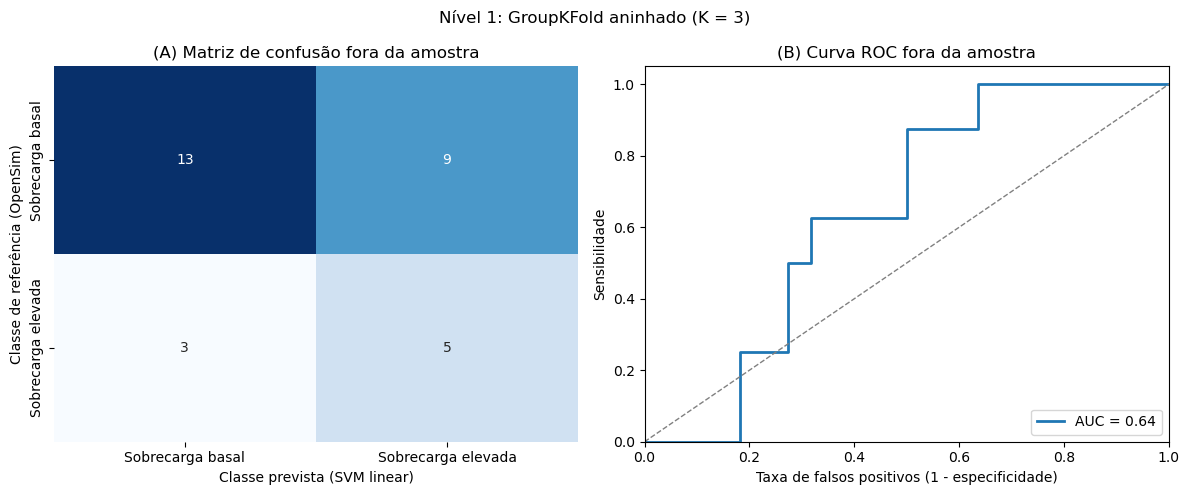

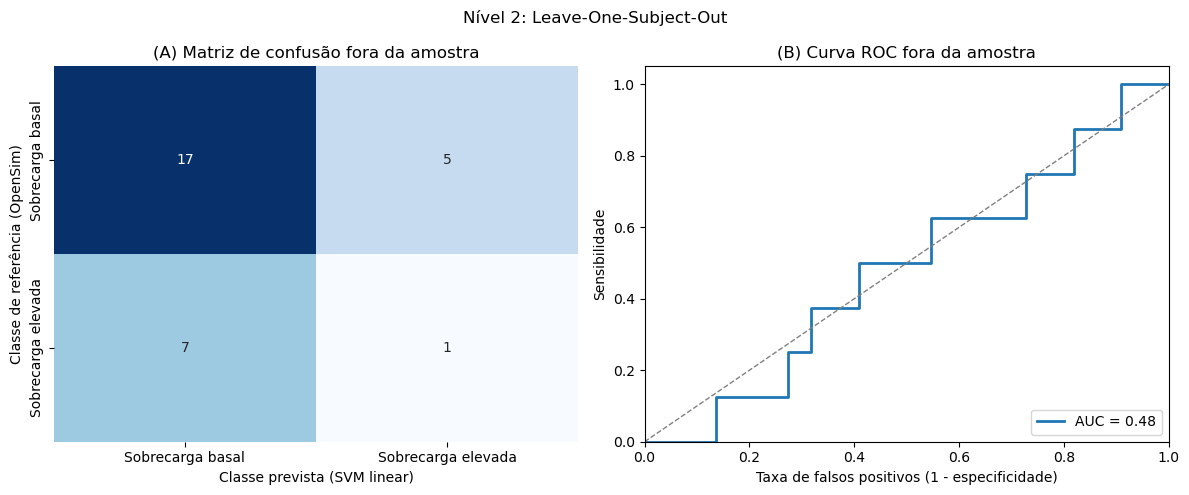


CONCLUIDO
Arquivos salvos em: C:\JG\opensim\Resultados_FASE3


In [2]:
"""
FASE 5: Validacao do SVM linear com o desfecho frontal (momento em valgo, Nm/kg)
=====================================================================
Dissertacao: LCA / cutting / OpenSim / SVM linear (PPGMSB - UNEB)

O que este script corrige em relacao ao pipeline-svm-groupkfold-v3:
  1. MASSAS REAIS: a massa de cada atleta e lida do modelo .osim escalonado
     (mesma rotina do script FASE 1b). O dicionario com valores redondos
     (75, 82, 70...) foi eliminado.
  2. MESMO ALVO NOS DOIS NIVEIS: pico do momento em valgo (Nm/kg), rotulado pelo P75
     da propria amostra. O LOSO antigo (fase1) usava o alvo em N absoluto.
  3. MIN-MAX SEM VAZAMENTO NOS DOIS NIVEIS: o scaler fica dentro do pipeline
     e e ajustado apenas no treino de cada particao.
  4. ESCORE DE DECISAO: a AUC e o ajuste de limiar usam decision_function do
     SVM, e nao predict_proba. O predict_proba depende de uma calibracao de
     Platt com validacao cruzada interna, instavel com 4 a 7 casos positivos.

Correspondencia com a subsecao 2.1.6:
  - 7 preditores; cisalhamento ML, compressao e momento normalizados por massa
  - cisalhamento AP excluido dos preditores (origem do rotulo)
  - class_weight='balanced'
  - Nivel 1: GroupKFold aninhado (K=3), limiar por G-Mean no laco interno
  - Nivel 2: LOSO + cluster bootstrap por atleta (2.000 replicas), IC 95%
  - baseline trivial da classe majoritaria
  - pesos do vetor w (descritivos, com sinal)

Saidas (na pasta PASTA_SAIDA):
  - fase5_resultados.txt          (todo o relatorio impresso)
  - fase5_predicoes_oof.csv       (predicoes fora da amostra, ciclo a ciclo)
  - fase5_pesos.csv               (pesos do SVM)
  - fase5_nivel1.png / fase5_nivel2.png (matriz de confusao + ROC, 600 dpi)

Requisitos: pandas, numpy, scikit-learn, matplotlib, seaborn, openpyxl
"""

import glob
import os
import sys
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix)

# ============================================================================
# 0. CONFIGURACOES (confira os caminhos)
# ============================================================================
CAMINHO_EXCEL = r'C:\JG\opensim\Resultados_FASE3\dataset_desfecho_frontal.xlsx'
PASTA_ZENODO = (r'C:\JG\opensim\Dados_Zenodo'
                r'\Nitschke_et_al_Change_of_Direction_Marker_Simulation')
PASTA_SAIDA = r'C:\JG\opensim\Resultados_FASE3'

RANDOM_STATE = 42
N_BOOTSTRAP = 2000
PERCENTIL = 0.75

# Massas impressas pelo script FASE 1b (1 casa decimal), usadas apenas para
# CONFERENCIA. O valor usado no calculo e o lido diretamente do .osim.
MASSAS_FASE1B = {'03': 58.8, '04': 84.2, '05': 64.9, '06': 77.7, '07': 57.7,
                 '08': 65.7, '09': 97.2, '10': 71.8, '11': 67.8}

COL_PARTICIPANTE = 'Participante'
COL_AP = 'Momento_Valgo_Pico_Nm'         # em Nm (alvo antes da normalizacao)
COLS_ANGULOS = ['Angulo_Aducao_Quadril', 'Angulo_Flexao_Joelho',
                'Angulo_Flexao_Quadril', 'Angulo_Rotacao_Quadril']
COLS_POR_MASSA = {  # coluna original -> nome normalizado
    'Momento_Aducao_Quadril': 'Momento_Aducao_Quadril_Nm_kg',
    'Cisalhamento_ML': 'Cisalhamento_ML_N_kg',
    'Compressao_Y': 'Compressao_Y_N_kg',
}
FEATURES = COLS_ANGULOS + list(COLS_POR_MASSA.values())


class Tee:
    """Imprime na tela e grava no arquivo ao mesmo tempo."""
    def __init__(self, caminho):
        self.arquivo = open(caminho, 'w', encoding='utf-8')
        self.tela = sys.stdout

    def write(self, texto):
        self.tela.write(texto)
        self.arquivo.write(texto)

    def flush(self):
        self.tela.flush()
        self.arquivo.flush()


def titulo(texto):
    print('\n' + '=' * 78)
    print(texto)
    print('=' * 78)


# ============================================================================
# 1. MASSAS REAIS A PARTIR DOS MODELOS .OSIM ESCALONADOS
# ============================================================================
def massa_total_osim(caminho_osim):
    raiz = ET.parse(caminho_osim).getroot()
    massas = [float(b.find('mass').text) for b in raiz.iter('Body')
              if b.find('mass') is not None and b.find('mass').text]
    if not massas:
        raise ValueError(f'Nenhuma tag <mass> em {caminho_osim}')
    return sum(massas)


def coletar_massas(participantes):
    massas = {}
    for p in participantes:
        achados = glob.glob(os.path.join(PASTA_ZENODO, f'Participant_{p}', '**',
                                         f'Participant_{p}.osim'), recursive=True)
        if not achados:
            raise FileNotFoundError(f'Modelo .osim do Participante {p} nao encontrado.')
        massas[p] = massa_total_osim(achados[0])

    titulo('MASSA CORPORAL POR ATLETA (modelo .osim escalonado)')
    for p in sorted(massas):
        ref = MASSAS_FASE1B.get(p)
        aviso = ''
        if ref is not None and abs(massas[p] - ref) > 0.1:
            aviso = f'  <-- ATENCAO: difere da FASE 1b ({ref} kg)'
        print(f'  Participante {p}: {massas[p]:.2f} kg{aviso}')
    return massas


# ============================================================================
# 2. CARREGAMENTO, NORMALIZACAO POR MASSA E ROTULAGEM (P75 em N/kg)
# ============================================================================
def padronizar_id(valor):
    return str(int(float(valor))).zfill(2)


def carregar_dados():
    df = pd.read_excel(CAMINHO_EXCEL)
    necessarias = [COL_PARTICIPANTE, COL_AP] + COLS_ANGULOS + list(COLS_POR_MASSA)
    faltando = [c for c in necessarias if c not in df.columns]
    if faltando:
        raise KeyError(f'Colunas ausentes no Excel: {faltando}\n'
                       f'Colunas disponiveis: {list(df.columns)}')

    df[COL_PARTICIPANTE] = df[COL_PARTICIPANTE].apply(padronizar_id)
    massas = coletar_massas(sorted(df[COL_PARTICIPANTE].unique()))
    df['Massa_kg'] = df[COL_PARTICIPANTE].map(massas)

    for original, normalizada in COLS_POR_MASSA.items():
        df[normalizada] = df[original] / df['Massa_kg']
    df['Desfecho_Nm_kg'] = df[COL_AP] / df['Massa_kg']

    df = df.dropna(subset=FEATURES + ['Desfecho_Nm_kg']).reset_index(drop=True)

    limiar = df['Desfecho_Nm_kg'].quantile(PERCENTIL)
    df['Classe'] = (df['Desfecho_Nm_kg'] >= limiar).astype(int)

    titulo('ESTRUTURA AMOSTRAL E ROTULAGEM')
    print(f'Ciclos: {len(df)} | Atletas: {df[COL_PARTICIPANTE].nunique()}')
    print(f'Limiar P75 do momento em valgo normalizado: {limiar:.3f} Nm/kg')
    print(f'Classe 1 (elevada sobrecarga): {df.Classe.sum()} | '
          f'Classe 0: {(df.Classe == 0).sum()}')
    if df.Classe.sum() != 7:
        print('ATENCAO: a Classe 1 nao tem 7 ciclos. Ajuste o texto da 2.1.6 '
              '(n da Classe 1 e da Classe 0) ao valor acima.')

    print('\nCiclos de Classe 1 por atleta:')
    print(df.groupby(COL_PARTICIPANTE)['Classe'].agg(['sum', 'count'])
            .rename(columns={'sum': 'classe_1', 'count': 'ciclos'}).T.to_string())

    print(f'Momento em valgo (Nm/kg): minimo {df.Desfecho_Nm_kg.min():.3f} | '
          f'mediana {df.Desfecho_Nm_kg.median():.3f} | maximo {df.Desfecho_Nm_kg.max():.3f}')
    return df


# ============================================================================
# 3. MODELO E METRICAS
# ============================================================================
def novo_modelo():
    return make_pipeline(MinMaxScaler(),
                         SVC(kernel='linear', C=1.0, class_weight='balanced',
                             random_state=RANDOM_STATE))


def limiar_gmean(y, escore):
    if len(np.unique(y)) < 2:
        return 0.0
    fpr, tpr, limiares = roc_curve(y, escore)
    gmean = np.sqrt(tpr * (1 - fpr))
    limiar = limiares[np.argmax(gmean)]
    return 0.0 if not np.isfinite(limiar) else limiar


def metricas(y, pred, escore):
    return {
        'acuracia': accuracy_score(y, pred),
        'precisao': precision_score(y, pred, zero_division=0),
        'sensibilidade': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'auc': roc_auc_score(y, escore) if len(np.unique(y)) > 1 else np.nan,
    }


def imprimir_metricas(nome, m, y):
    print(f'\n{nome}')
    print(f'  Acuracia global: {m["acuracia"]*100:.1f}%')
    print(f'  Precisao (C1):   {m["precisao"]*100:.1f}%')
    print(f'  Sensib. (C1):    {m["sensibilidade"]*100:.1f}%')
    print(f'  F1 (C1):         {m["f1"]:.2f}')
    print(f'  AUC-ROC:         {m["auc"]:.2f}')
    print(f'  Baseline trivial (classe majoritaria): {(1 - y.mean())*100:.1f}%')


# ============================================================================
# 4. NIVEL 1: GROUPKFOLD ANINHADO (K=3), LIMIAR POR G-MEAN NO LACO INTERNO
# ============================================================================
def nivel1(df):
    X, y = df[FEATURES].to_numpy(float), df['Classe'].to_numpy()
    g = df[COL_PARTICIPANTE].to_numpy()
    escore, pred = np.full(len(y), np.nan), np.full(len(y), -1)
    pesos = []

    titulo('NIVEL 1: GROUPKFOLD ANINHADO (K = 3)')
    for k, (tr, te) in enumerate(GroupKFold(n_splits=3).split(X, y, g), 1):
        # Laco interno: escores fora da amostra apenas dentro do treino externo
        y_in, s_in = [], []
        for tr_i, te_i in GroupKFold(n_splits=3).split(X[tr], y[tr], g[tr]):
            if len(np.unique(y[tr][tr_i])) < 2:
                continue
            m_in = novo_modelo().fit(X[tr][tr_i], y[tr][tr_i])
            y_in.extend(y[tr][te_i])
            s_in.extend(m_in.decision_function(X[tr][te_i]))
        limiar = limiar_gmean(np.array(y_in), np.array(s_in))

        modelo = novo_modelo().fit(X[tr], y[tr])
        escore[te] = modelo.decision_function(X[te])
        pred[te] = (escore[te] >= limiar).astype(int)
        pesos.append(modelo[-1].coef_.ravel())

        print(f'Particao {k}: atletas de teste {sorted(set(g[te]))} | '
              f'C1 treino {y[tr].sum()} / teste {y[te].sum()} | '
              f'limiar interno {limiar:.3f}')

    m = metricas(y, pred, escore)
    imprimir_metricas(f'Resultado agregado fora da amostra ({len(y)} ciclos):', m, y)
    return escore, pred, np.array(pesos), m


# ============================================================================
# 5. NIVEL 2: LOSO + CLUSTER BOOTSTRAP POR ATLETA
# ============================================================================
def nivel2(df):
    X, y = df[FEATURES].to_numpy(float), df['Classe'].to_numpy()
    g = df[COL_PARTICIPANTE].to_numpy()
    escore, pred = np.full(len(y), np.nan), np.full(len(y), -1)
    pesos = []

    titulo('NIVEL 2: LEAVE-ONE-SUBJECT-OUT (LOSO)')
    for tr, te in LeaveOneGroupOut().split(X, y, g):
        atleta = g[te][0]
        if len(np.unique(y[tr])) < 2:
            print(f'Atleta {atleta}: treino com uma so classe, particao ignorada.')
            continue
        modelo = novo_modelo().fit(X[tr], y[tr])
        escore[te] = modelo.decision_function(X[te])
        pred[te] = modelo.predict(X[te])
        pesos.append(modelo[-1].coef_.ravel())
        acertos = int((pred[te] == y[te]).sum())
        print(f'Atleta {atleta}: C1 no treino {y[tr].sum()} | C1 no teste '
              f'{y[te].sum()} | acertos {acertos}/{len(te)} | '
              f'escores {np.round(escore[te], 2).tolist()}')

    ok = ~np.isnan(escore)
    m = metricas(y[ok], pred[ok], escore[ok])
    imprimir_metricas('Resultado agregado fora da amostra:', m, y[ok])

    # Cluster bootstrap por atleta
    rng = np.random.default_rng(RANDOM_STATE)
    atletas = np.unique(g[ok])
    reps = {k: [] for k in m}
    for _ in range(N_BOOTSTRAP):
        amostra = rng.choice(atletas, size=len(atletas), replace=True)
        idx = np.concatenate([np.where((g == a) & ok)[0] for a in amostra])
        if len(np.unique(y[idx])) < 2:
            continue
        for k, v in metricas(y[idx], pred[idx], escore[idx]).items():
            reps[k].append(v)

    print(f'\nIC 95% por cluster bootstrap ({N_BOOTSTRAP} replicas; '
          f'validas: {len(reps["auc"])}):')
    ic = {}
    for k, v in reps.items():
        v = np.array(v)
        ic[k] = (np.percentile(v, 2.5), np.percentile(v, 97.5))
        print(f'  {k:14s}: {m[k]:.3f}  [IC 95%: {ic[k][0]:.3f} a {ic[k][1]:.3f}]')
    return escore, pred, np.array(pesos), m, ic


# ============================================================================
# 6. PESOS DO SVM (DESCRITIVOS)
# ============================================================================
def pesos_svm(df, pesos_n1, pesos_n2):
    X, y = df[FEATURES].to_numpy(float), df['Classe'].to_numpy()
    w_total = novo_modelo().fit(X, y)[-1].coef_.ravel()
    tabela = pd.DataFrame({
        'Variavel': FEATURES,
        'Peso_modelo_todos_ciclos': w_total,
        'Media_Nivel1': pesos_n1.mean(axis=0), 'DP_Nivel1': pesos_n1.std(axis=0, ddof=1),
        'Media_LOSO': pesos_n2.mean(axis=0), 'DP_LOSO': pesos_n2.std(axis=0, ddof=1),
    }).sort_values('Peso_modelo_todos_ciclos', key=np.abs, ascending=False)

    titulo('PESOS DO VETOR w (com sinal; interpretacao descritiva, nao causal)')
    print(tabela.round(3).to_string(index=False))
    print('\nSinal positivo: o aumento da variavel aproxima o ciclo da Classe 1.')
    print('As particoes do LOSO compartilham 7/8 do treino; o DP entre particoes'
          ' subestima a incerteza real dos pesos.')
    return tabela


# ============================================================================
# 7. FIGURAS
# ============================================================================
def figura(y, pred, escore, auc_valor, titulo_fig, caminho):
    ok = ~np.isnan(escore)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(confusion_matrix(y[ok], pred[ok], labels=[0, 1]), annot=True,
                fmt='d', cmap='Blues', cbar=False, ax=ax1,
                xticklabels=['Sobrecarga basal', 'Sobrecarga elevada'],
                yticklabels=['Sobrecarga basal', 'Sobrecarga elevada'])
    ax1.set_title('(A) Matriz de confusão fora da amostra')
    ax1.set_ylabel('Classe de referência (OpenSim)')
    ax1.set_xlabel('Classe prevista (SVM linear)')

    fpr, tpr, _ = roc_curve(y[ok], escore[ok])
    ax2.plot(fpr, tpr, lw=2, label=f'AUC = {auc_valor:.2f}')
    ax2.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
    ax2.set_xlim(0, 1); ax2.set_ylim(0, 1.05)
    ax2.set_xlabel('Taxa de falsos positivos (1 - especificidade)')
    ax2.set_ylabel('Sensibilidade')
    ax2.set_title('(B) Curva ROC fora da amostra')
    ax2.legend(loc='lower right')
    fig.suptitle(titulo_fig)
    plt.tight_layout()
    plt.savefig(caminho, dpi=600)
    plt.show()


# ============================================================================
# EXECUCAO
# ============================================================================
if __name__ == '__main__':
    os.makedirs(PASTA_SAIDA, exist_ok=True)
    sys.stdout = Tee(os.path.join(PASTA_SAIDA, 'fase5_resultados.txt'))

    df = carregar_dados()
    y = df['Classe'].to_numpy()

    s1, p1, w1, m1 = nivel1(df)
    s2, p2, w2, m2, ic2 = nivel2(df)
    tabela_pesos = pesos_svm(df, w1, w2)

    figura(y, p1, s1, m1['auc'], 'Nível 1: GroupKFold aninhado (K = 3)',
           os.path.join(PASTA_SAIDA, 'fase5_nivel1.png'))
    figura(y, p2, s2, m2['auc'], 'Nível 2: Leave-One-Subject-Out',
           os.path.join(PASTA_SAIDA, 'fase5_nivel2.png'))

    df.assign(escore_n1=s1, pred_n1=p1, escore_loso=s2, pred_loso=p2)[
        [COL_PARTICIPANTE, 'Massa_kg', COL_AP, 'Desfecho_Nm_kg', 'Classe',
         'escore_n1', 'pred_n1', 'escore_loso', 'pred_loso']
    ].to_csv(os.path.join(PASTA_SAIDA, 'fase5_predicoes_oof.csv'),
             index=False, sep=';', decimal=',')
    tabela_pesos.to_csv(os.path.join(PASTA_SAIDA, 'fase5_pesos.csv'),
                        index=False, sep=';', decimal=',')

    titulo('CONCLUIDO')
    print(f'Arquivos salvos em: {PASTA_SAIDA}')
    sys.stdout = sys.stdout.tela